## RAGAS

`RAGAS` 是社区使用最广的RAG评估框架，提供多个核心指标覆盖检索和生成全流程
- 检索质量——搜对了吗？ Recall、Precision、MRR
- 生成质量——回答对了吗？ Faithfulness、Relevancy

资料笔记：https://my.feishu.cn/wiki/HunhwoZ6HiijZ3kH5dTcK8j7nBd

### 1. 评估数据说明

新版 RAGAS 使用 `ragas.Dataset`（替代旧的 HuggingFace Dataset）

新版数据集要求以下4个字段：

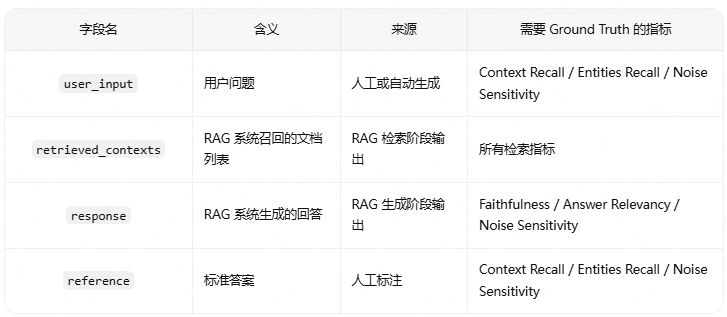

数据集示例（`ragas.Dataset` 单行）：

```
{
    "user_input": "孔子的教育思想有哪些？",
    "retrieved_contexts": [
        "孔子主张有教无类，认为人人都应该接受教育...",
        "孔子提出因材施教、启发诱导等教学原则..."
    ],
    "response": "孔子主张有教无类，提出因材施教、启发诱导、学思结合等教学原则。",
    "reference": "孔子主张有教无类，提出因材施教、启发诱导、学思结合、谦虚笃实四大教学原则。教育目的是培养士和君子。"
}
```

旧 API 字段名对照：
- question → user_input
- contexts → retrieved_contexts
- answer → response
- ground_truth → reference

新版本中这些字段名是强制的。

### 2. 安装 RAGAS

```
uv add ragas
```

注意安装的版本，ragas最新是 `0.4.3` 版本，如果安装的版本不对可以在 `pyproject.toml` 中修改版本号。

### 3. RAGAS 核心指标详解

RAGAS 在"RAG评估"类别下提供8个指标（6个文本 + 2个多模态）。下面逐一说明 **6个核心文本指标**。
```
用户问题 ──→ 检索阶段 ──────────────→ 生成阶段 ──────────→ 回答
              │                           │
              ├─ Context Precision        ├─ Faithfulness
              ├─ Context Recall           ├─ Response Relevancy
              ├─ Context Entities Recall  └─ Noise Sensitivity
              └─ (检索质量)

```

检索阶段
- `Context Precision （上下文精度）`：前 K 个检索结果中，相关文档排得越靠前贡献越大（怕偏）
- `Context Recall（上下文召回率）`：`Reference`（参考答案）中的信息点，检索出来的资料中覆盖了多少（怕漏）
- `Context Entities Recall（上下文实体召回率）`：`Reference`（参考答案）中的实体，检索出来的资料中覆盖了多少（怕漏）

生成阶段
- `Faithfulness （忠实性 / 反幻觉）`：模型回答中每一个事实陈述是否都能从检索文档中找到依据？检测"幻觉"的核心指标
- `Response Relevancy（回答相关性 / 切题度）`：模型的回答是否紧扣用户问题？有没有答非所问或跑题？
- `Noise Sensitivity（噪声敏感度）`：系统在利用检索文档时，产生错误回答的频率有多高？噪声敏感度越低，系统越鲁棒。

#### 3.1 Context Presion@K

$$ \text{Context Precision@K} = \frac{\sum_{k=1}^{K} (\text{Precision@k} \times v_k)}{\text{Top K 结果中相关片段的总数}} $$

- v_k 是一个 0/1 列表，表示第 k 个片段是否相关
- Precision@k 为前k个片段中相关片段的比例，即 `Precision@k = (Top K 结果中相关片段的总数 / k)`


In [2]:
import numpy as np
def _calculate_average_precision(verdict_list) -> float:
    score = np.nan
    numerator = sum(
        [
            (sum(verdict_list[: i + 1]) / (i + 1)) * verdict_list[i]
            for i in range(len(verdict_list)) # i= 0,1,2,3,4
        ]
    )
    denominator = sum(verdict_list) + 1e-10
    print(denominator)
    print(numerator)
    score = numerator / denominator
    return score
# 1--相关的文档片段，0，不相关的文档片段
verdict_list = [1, 0, 1, 1, 0]
score = _calculate_average_precision(verdict_list)
print("score1:",score)  # 输出结果
'''
i= 0,1,2,3,4
# Precision@k = (Top K 结果中相关片段的总数 / k)
第一个片段：(1 / 0+1) * 1 = 1
第二个片段：(1 / 1+1) * 0 = 0
第三个片段：(2 / 2+1) * 1 = 0.6667
第四个片段：(3 / 3+1) * 1 = 0.75
第五个片段：(3 / 4+1) * 0 = 0
分子总和：1 + 0 + 0.6667 + 0.75 + 0 = 2.4167
相关片段的总数为3，所以分母为3
最终得分：2.4167 / 3 ≈ 0.8056
'''

verdict_list = [1, 1, 0, 1, 0]
score = _calculate_average_precision(verdict_list)
print("score2:",score)  # 输出结果

3.0000000001
2.4166666666666665
score1: 0.8055555555287036
3.0000000001
2.75
score2: 0.9166666666361111


### 4. 最小可执行案例

In [1]:
import ragas
print(ragas.__version__)

E:\Agent\L2阶段\langchain_tutorial\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


0.4.3


In [3]:
from ragas import evaluate, EvaluationDataset
from ragas.embeddings import LangchainEmbeddingsWrapper # from ragas.llms import llm_factory
from ragas.llms import LangchainLLMWrapper              # from ragas.embeddings.base import embedding_factory
from ragas.metrics import (
    answer_relevancy,  # 回答相关性
    faithfulness,      # 忠实度
    context_recall,    # 上下文召回率
    context_precision, # 上下文精度
)

import os
from langchain_openai import ChatOpenAI
llm = ChatOpenAI(
    api_key=os.getenv("DASHSCOPE_API_KEY"),
    model="qwen3.7-max",
    base_url="https://ws-ots0tb33v08803wb.cn-beijing.maas.aliyuncs.com/compatible-mode/v1",
    extra_body={"enable_thinking": False}
)
from langchain_community.embeddings import DashScopeEmbeddings
embeddings = DashScopeEmbeddings(
    model="text-embedding-v4",
    dashscope_api_key=os.getenv("DASHSCOPE_API_KEY")
)

# 1) 评审模型（建议 temperature=0，降低打分波动）
evaluator_llm = LangchainLLMWrapper(llm)
evaluator_embeddings = LangchainEmbeddingsWrapper(embeddings)

# 2) 新版字段名：user_input / response / retrieved_contexts / reference
samples = [
    {
        "user_input": "RAGAS 用来做什么？",
        "response": "RAGAS 是一个用于评估 RAG 系统的框架。",
        "retrieved_contexts": [
            "RAGAS 是 RAG 评估框架，可评估检索和生成质量。"
        ],
        "reference": "RAGAS 是评估 RAG 系统的框架。",
    },
    {
        "user_input": "Faithfulness 指标衡量什么？",
        "response": "Faithfulness 衡量答案是否由检索到的上下文支持。",
        "retrieved_contexts": [
            "Faithfulness 用于判断答案中的陈述是否被上下文支持，可检测幻觉。"
        ],
        "reference": "Faithfulness 衡量生成答案对检索上下文的忠实程度。",
    },
]

dataset = EvaluationDataset.from_list(samples)

# 4) 评估
result = evaluate(
    dataset=dataset,
    llm=evaluator_llm,
    embeddings=evaluator_embeddings,
    metrics=[
        answer_relevancy,
        context_recall,
        faithfulness,
        context_precision,
    ],
    raise_exceptions=False
)

print(result)          # 汇总分数
print(result.to_pandas())  # 逐样本分数

df = result.to_pandas()
df.to_csv('ragas_reval.csv', index=True)

C:\Users\user\AppData\Local\Temp\ipykernel_8996\2795748849.py:4: DeprecationWarning: Importing answer_relevancy from 'ragas.metrics' is deprecated and will be removed in v1.0. Please use 'ragas.metrics.collections' instead. Example: from ragas.metrics.collections import answer_relevancy
  from ragas.metrics import (
C:\Users\user\AppData\Local\Temp\ipykernel_8996\2795748849.py:4: DeprecationWarning: Importing faithfulness from 'ragas.metrics' is deprecated and will be removed in v1.0. Please use 'ragas.metrics.collections' instead. Example: from ragas.metrics.collections import faithfulness
  from ragas.metrics import (
C:\Users\user\AppData\Local\Temp\ipykernel_8996\2795748849.py:4: DeprecationWarning: Importing context_recall from 'ragas.metrics' is deprecated and will be removed in v1.0. Please use 'ragas.metrics.collections' instead. Example: from ragas.metrics.collections import context_recall
  from ragas.metrics import (
C:\Users\user\AppData\Local\Temp\ipykernel_8996\2795748849

{'answer_relevancy': 0.8494, 'context_recall': 1.0000, 'faithfulness': 1.0000, 'context_precision': 1.0000}
             user_input                        retrieved_contexts  \
0          RAGAS 用来做什么？            [RAGAS 是 RAG 评估框架，可评估检索和生成质量。]   
1  Faithfulness 指标衡量什么？  [Faithfulness 用于判断答案中的陈述是否被上下文支持，可检测幻觉。]   

                         response                        reference  \
0        RAGAS 是一个用于评估 RAG 系统的框架。             RAGAS 是评估 RAG 系统的框架。   
1  Faithfulness 衡量答案是否由检索到的上下文支持。  Faithfulness 衡量生成答案对检索上下文的忠实程度。   

   answer_relevancy  context_recall  faithfulness  context_precision  
0          0.840426             1.0           1.0                1.0  
1          0.858287             1.0           1.0                1.0  
